In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys, os
# add the repo root (the folder containing config.py) to the path, from any depth
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "config.py")) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)

In [ ]:
import config, pandas as pd, matplotlib.pyplot as plt
from cprics.io_data import load_peak_amplitudes
from cprics.islands import build_all_islands
from cprics.tracking import track_islands
from cprics.evaluate import lead_time_table, early_warning_date
from cprics.series import site_trajectory, current_segment
from cprics.predict import forecast_crossing

pk  = load_peak_amplitudes(config.PEAK_AMP_DIR, "9_top_right")
isl = track_islands(build_all_islands(pk, wavelength=9))

per_site = isl.groupby("site_id")["date"].nunique()
print("tracked sites:", len(per_site),
      "| seen on >=3 dates:", (per_site >= 3).sum(),
      "| >=5 dates:", (per_site >= 5).sum())

tracked sites: 167 | seen on >=3 dates: 102 | >=5 dates: 88


In [2]:
TARGET = config.CATEGORY_THRESHOLDS["I"]     # 30 mm (same target as the CYC run, for comparison)
lt = lead_time_table(isl, threshold=TARGET)
warned = lt[lt["lead_days"].notna()]
print(f"Sites reaching {TARGET} mm: {len(lt)}")
print(f"  warned early: {len(warned)} ({100*len(warned)/max(len(lt),1):.0f}%)")
if len(warned):
    print(f"  median advance notice: {warned['lead_days'].median():.0f} days "
          f"({warned['lead_days'].median()/7:.1f} weeks)")
lt.sort_values('lead_days', ascending=False).head(10)

Sites reaching 30 mm: 14
  warned early: 4 (29%)
  median advance notice: 266 days (38.1 weeks)


,site_id,actual_crossing,alarm_date,lead_days
7,CRR2_1100_9R_91,2026-04-05,2025-06-01,308.0
3,CNB1_1100_9R_46,2026-02-09,2025-05-05,280.0
9,CWK1_2100_9R_106,2026-02-09,2025-06-01,253.0
8,CRR2_1100_9R_95,2026-06-28,2026-05-31,28.0
0,CNB1_1100_9R_39,2025-01-13,NaT,NaN
1,CNB1_1100_9R_41,2026-07-27,NaT,NaN
2,CNB1_1100_9R_42,2025-01-13,NaT,NaN
4,CNB1_1100_9R_47,2025-04-07,NaT,NaN
5,CNB1_3400_9R_66,2025-01-13,NaT,NaN
6,CNB3_3400_9R_72,2025-01-13,NaT,NaN


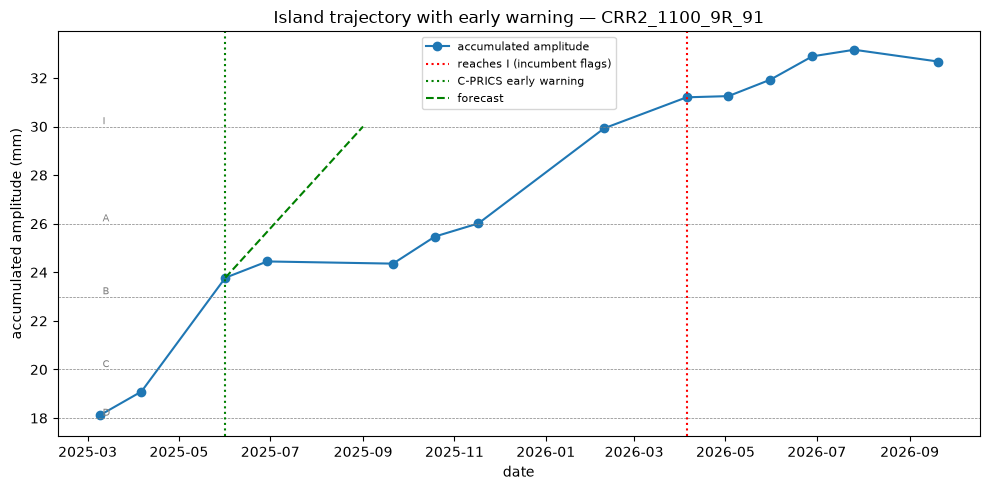

In [3]:
site = warned.sort_values("lead_days", ascending=False)["site_id"].iloc[0]
traj = site_trajectory(isl, site)
alarm, actual = early_warning_date(traj, TARGET)
seg = current_segment(traj[traj["date"] <= alarm])
pred = forecast_crossing(seg, TARGET)

plt.figure(figsize=(10, 5))
plt.plot(traj["date"], traj["amplitude"], "o-", label="accumulated amplitude")
for cat, thr in config.CATEGORY_THRESHOLDS.items():
    plt.axhline(thr, ls="--", lw=0.5, color="grey")
    plt.text(traj["date"].min(), thr, f" {cat}", fontsize=7, color="grey", va="bottom")
plt.axvline(actual, ls=":", color="red", label="reaches I (incumbent flags)")
plt.axvline(alarm, ls=":", color="green", label="C-PRICS early warning")
if pred is not None:
    plt.plot([seg["date"].iloc[-1], pred], [seg["amplitude"].iloc[-1], TARGET],
             "--", color="green", label="forecast")
plt.title(f"Island trajectory with early warning — {site}")
plt.ylabel("accumulated amplitude (mm)"); plt.xlabel("date"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
from cprics.risk import risk_score
THRESH = 0.5          # "high risk" flag level

recs = []
for sid, g in isl.groupby("site_id"):
    traj = site_trajectory(isl, sid)
    crossing = traj.loc[traj.amplitude >= 30, "date"]
    crossing = crossing.iloc[0] if len(crossing) else pd.NaT
    flagged = pd.NaT
    for k in range(2, len(traj) + 1):
        if risk_score(traj.iloc[:k]) >= THRESH:
            flagged = traj.date.iloc[k - 1]; break
    recs.append({"site_id": sid, "reaches_I": traj.amplitude.max() >= 30,
                 "crossing": crossing, "flagged": flagged})
R = pd.DataFrame(recs)

# detection lead: flagged before reaching I
hit = R[R.reaches_I & R.flagged.notna() & R.crossing.notna() & (R.flagged < R.crossing)]
print("sites reaching I:", int(R.reaches_I.sum()))
print(f"  flagged before they reached I: {len(hit)} "
      f"({100*len(hit)/max(int(R.reaches_I.sum()),1):.0f}%)")
print(f"  median detection lead: {(hit.crossing - hit.flagged).dt.days.median():.0f} days "
      f"({(hit.crossing - hit.flagged).dt.days.median()/7:.0f} weeks)")

# precision: of everything we flag, how much actually reaches I
flagged = R[R.flagged.notna()]
print(f"precision: {100*flagged.reaches_I.mean():.0f}% of {len(flagged)} flagged sites reach I")

sites reaching I: 14
  flagged before they reached I: 4 (29%)
  median detection lead: 336 days (48 weeks)
precision: 31% of 35 flagged sites reach I
